In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Lokasi proyek:
# Notebook berada di folder PythonEDA/notebooks
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"

# Membuat folder output jika belum tersedia
for folder in [FIGURE_DIR, TABLE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DATA_FILE = DATA_DIR / "Online Retail.xlsx"

if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"File tidak ditemukan: {DATA_FILE}\n"
        "Pastikan Online Retail.xlsx berada di folder data."
    )

print("Folder proyek:", PROJECT_DIR)
print("File dataset:", DATA_FILE)
print("Folder output:", OUTPUT_DIR)


Folder proyek: C:\Users\HP GK\DataAnalyst\PythonEDA
File dataset: C:\Users\HP GK\DataAnalyst\PythonEDA\data\Online Retail.xlsx
Folder output: C:\Users\HP GK\DataAnalyst\PythonEDA\outputs


In [2]:
df = pd.read_excel(DATA_FILE)

print("Ukuran dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

print("\nLima baris pertama:")
display(df.head())

print("\nInformasi tipe data:")
df.info()

Ukuran dataset: (541909, 8)

Nama kolom:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Lima baris pertama:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Informasi tipe data:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [3]:
print("Statistik deskriptif:")
display(df.describe(include="all").T)

print("\nJumlah nilai kosong per kolom:")
display(df.isnull().sum().to_frame("missing_values"))

print("\nJumlah baris duplikat:", df.duplicated().sum())

print("\nRentang tanggal mentah:")
print(df["InvoiceDate"].min(), "sampai", df["InvoiceDate"].max())

Statistik deskriptif:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Jumlah nilai kosong per kolom:


,missing_values
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0



Jumlah baris duplikat: 5268

Rentang tanggal mentah:
2010-12-01 08:26:00 sampai 2011-12-09 12:50:00


In [4]:
# Memeriksa nilai negatif dan transaksi pembatalan
print("Jumlah Quantity negatif:", (df["Quantity"] < 0).sum())
print("Jumlah UnitPrice negatif:", (df["UnitPrice"] < 0).sum())

print(
    "Jumlah invoice pembatalan:",
    df["InvoiceNo"].astype(str).str.startswith("C").sum()
)

print(
    "Baris tanpa CustomerID:",
    df["CustomerID"].isna().sum()
)

print(
    "Baris tanpa Description:",
    df["Description"].isna().sum()
)

# Melihat contoh transaksi dengan Quantity negatif
display(
    df.loc[df["Quantity"] < 0].head(10)
)

# Melihat contoh transaksi dengan harga negatif
display(
    df.loc[df["UnitPrice"] < 0].head(10)
)

Jumlah Quantity negatif: 10624
Jumlah UnitPrice negatif: 2
Jumlah invoice pembatalan: 9288
Baris tanpa CustomerID: 135080
Baris tanpa Description: 1454


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [5]:

# ==========================================
# DATA CLEANING — ONLINE RETAIL
# ==========================================

# 1. Mulai dari data mentah
raw_df = df.copy()

# 2. Standarkan nama kolom
raw_df.columns = (
    raw_df.columns
    .str.strip()
    .str.replace(" ", "", regex=False)
)

# 3. Pastikan tipe data sesuai
raw_df["InvoiceDate"] = pd.to_datetime(
    raw_df["InvoiceDate"], errors="coerce"
)
raw_df["Quantity"] = pd.to_numeric(
    raw_df["Quantity"], errors="coerce"
)
raw_df["UnitPrice"] = pd.to_numeric(
    raw_df["UnitPrice"], errors="coerce"
)

# 4. Hapus duplikat identik
step1 = raw_df.drop_duplicates().copy()

# 5. Hapus baris dengan kolom transaksi utama yang tidak valid
step2 = step1.dropna(
    subset=["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice"]
).copy()

# 6. Pisahkan invoice pembatalan
is_cancelled = (
    step2["InvoiceNo"].astype(str).str.startswith("C")
)

cancelled_df = step2[is_cancelled].copy()
non_cancelled_df = step2[~is_cancelled].copy()

# 7. Pisahkan transaksi dengan kuantitas atau harga
# yang tidak positif untuk analisis penjualan reguler
invalid_values = (
    (non_cancelled_df["Quantity"] <= 0)
    | (non_cancelled_df["UnitPrice"] <= 0)
)

invalid_df = non_cancelled_df[invalid_values].copy()
clean_df = non_cancelled_df[~invalid_values].copy()

# 8. Hitung pendapatan
clean_df["Revenue"] = (
    clean_df["Quantity"] * clean_df["UnitPrice"]
)

# 9. Tambahkan kolom waktu
clean_df["Year"] = clean_df["InvoiceDate"].dt.year
clean_df["Month"] = clean_df["InvoiceDate"].dt.month
clean_df["YearMonth"] = (
    clean_df["InvoiceDate"].dt.to_period("M").astype(str)
)

# 10. Buat laporan tahapan cleaning
cleaning_report = pd.DataFrame({
    "Stage": [
        "Raw data",
        "After removing exact duplicates",
        "After removing invalid required fields",
        "Cancelled invoices excluded",
        "Non-cancelled invalid quantity/price rows excluded",
        "Final regular-sales dataset"
    ],
    "Rows": [
        len(raw_df),
        len(step1),
        len(step2),
        len(cancelled_df),
        len(invalid_df),
        len(clean_df)
    ]
})

display(cleaning_report)

print("\nFinal dataset shape:", clean_df.shape)
print("Remaining duplicate rows:", clean_df.duplicated().sum())
print("Missing CustomerID retained:", clean_df["CustomerID"].isna().sum())
print("Missing Description retained:", clean_df["Description"].isna().sum())

,Stage,Rows
0,Raw data,541909
1,After removing exact duplicates,536641
2,After removing invalid required fields,536641
3,Cancelled invoices excluded,9251
4,Non-cancelled invalid quantity/price rows excl...,2512
5,Final regular-sales dataset,524878



Final dataset shape: (524878, 12)
Remaining duplicate rows: 0
Missing CustomerID retained: 132186
Missing Description retained: 0


In [6]:
from pathlib import Path

TABLE_DIR.mkdir(parents=True, exist_ok=True)

cleaning_report.to_csv(
    TABLE_DIR / "cleaning_summary.csv",
    index=False
)

clean_df.to_csv(
    TABLE_DIR / "online_retail_clean.csv",
    index=False
)

print("Laporan cleaning berhasil disimpan.")
print("File: outputs/tables/cleaning_summary.csv")
print("File: outputs/tables/online_retail_clean.csv")

Laporan cleaning berhasil disimpan.
File: outputs/tables/cleaning_summary.csv
File: outputs/tables/online_retail_clean.csv


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Pastikan direktori output tersedia
for folder in [FIGURE_DIR, TABLE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Hitung KPI
total_revenue = clean_df["Revenue"].sum()
total_units = clean_df["Quantity"].sum()
total_invoices = clean_df["InvoiceNo"].nunique()
total_customers = clean_df["CustomerID"].nunique()
total_products = clean_df["StockCode"].nunique()
total_countries = clean_df["Country"].nunique()

average_order_value = (
    total_revenue / total_invoices if total_invoices else 0
)

kpi = pd.DataFrame({
    "Metric": [
        "Total Revenue (£)",
        "Total Units Sold",
        "Unique Invoices",
        "Unique Customers with ID",
        "Unique Products",
        "Countries",
        "Average Revenue per Invoice (£)"
    ],
    "Value": [
        round(total_revenue, 2),
        int(total_units),
        int(total_invoices),
        int(total_customers),
        int(total_products),
        int(total_countries),
        round(average_order_value, 2)
    ]
})

display(kpi)
kpi.to_csv(TABLE_DIR / "business_kpis.csv", index=False)


,Metric,Value
0,Total Revenue (£),10642110.80
1,Total Units Sold,5572420.00
2,Unique Invoices,19960.00
3,Unique Customers with ID,4338.00
4,Unique Products,3922.00
5,Countries,38.00
6,Average Revenue per Invoice (£),533.17


,YearMonth,Revenue,Units_Sold,Unique_Invoices,Revenue_Growth_Pct
0,2010-12,821452.730,358019,1559,NaN
1,2011-01,689811.610,387099,1086,-16.025404
2,2011-02,522545.560,282934,1100,-24.248077
3,2011-03,716215.260,376599,1454,37.062740
4,2011-04,536968.491,307953,1246,-25.026941
5,2011-05,769296.610,395001,1681,43.266620
6,2011-06,760547.010,388511,1533,-1.137351
7,2011-07,718076.121,399693,1475,-5.584256
8,2011-08,757841.380,421020,1361,5.537750
9,2011-09,1056435.192,569573,1837,39.400568


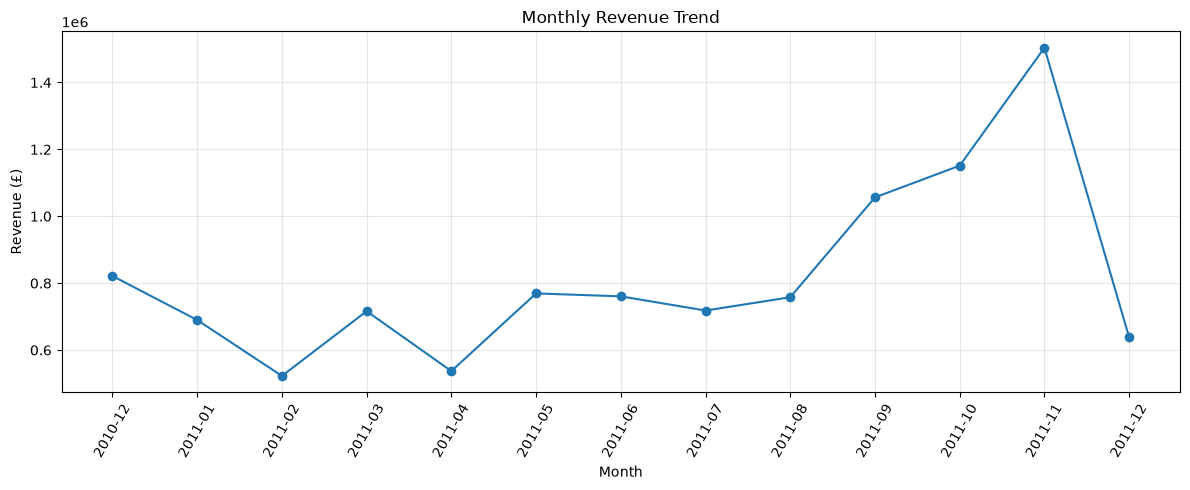

In [10]:
monthly_sales = (
    clean_df.groupby("YearMonth")
    .agg(
        Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum"),
        Unique_Invoices=("InvoiceNo", "nunique")
    )
    .reset_index()
    .sort_values("YearMonth")
)

monthly_sales["Revenue_Growth_Pct"] = (
    monthly_sales["Revenue"].pct_change() * 100
)

display(monthly_sales)
monthly_sales.to_csv(
    TABLE_DIR / "monthly_sales_trend.csv",
    index=False
)

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales["YearMonth"],
    monthly_sales["Revenue"],
    marker="o"
)
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "monthly_revenue_trend.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

,StockCode,Product_Description,Units_Sold,Revenue,Invoice_Count
3911,DOT,DOTCOM POSTAGE,706,206248.77,706
1235,22423,REGENCY CAKESTAND 3 TIER,13851,174156.54,1988
2390,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
3539,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37641,104462.75,2198
2468,47566,PARTY BUNTING,18283,99445.23,1685
3528,85099B,JUMBO BAG RED RETROSPOT,48371,94159.81,2089
1945,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247
3914,POST,POSTAGE,3150,78101.88,1126
3912,M,Manual,6984,77750.27,289
1867,23084,RABBIT NIGHT LIGHT,30739,66870.03,994


,StockCode,Product_Description,Units_Sold,Revenue,Invoice_Count
2390,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
1945,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247
1034,22197,SMALL POPCORN HOLDER,56898,51334.47,1392
2562,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,13814.01,535
3528,85099B,JUMBO BAG RED RETROSPOT,48371,94159.81,2089
3539,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37641,104462.75,2198
364,21212,PACK OF 72 RETROSPOT CAKE CASES,36396,21246.45,1320
2666,84879,ASSORTED COLOUR BIRD ORNAMENT,36362,58927.62,1455
1867,23084,RABBIT NIGHT LIGHT,30739,66870.03,994
1299,22492,MINI PAINT SET VINTAGE,26633,16937.82,380


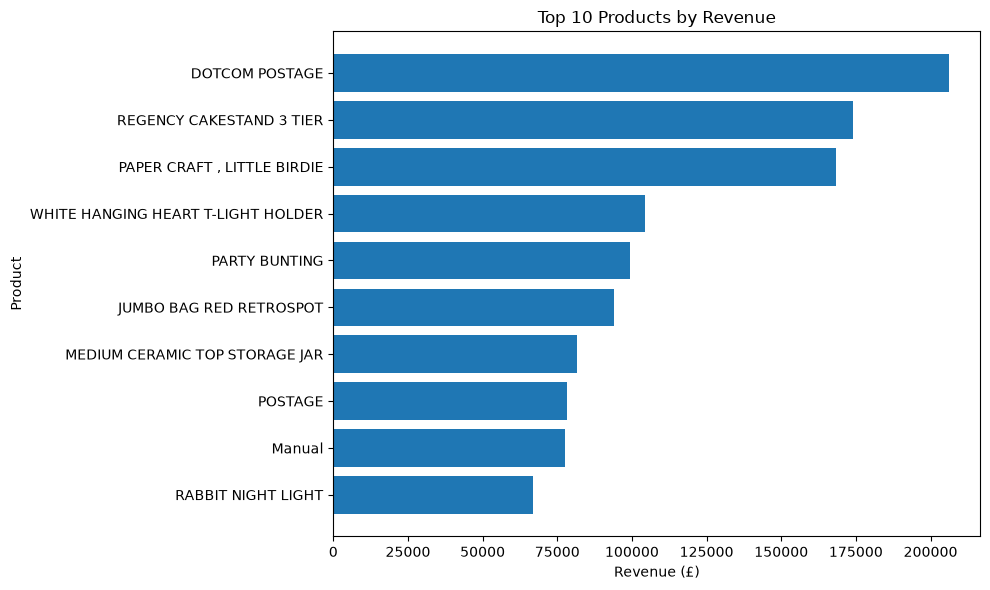

In [11]:
product_analysis = (
    clean_df.groupby("StockCode")
    .agg(
        Product_Description=("Description", "first"),
        Units_Sold=("Quantity", "sum"),
        Revenue=("Revenue", "sum"),
        Invoice_Count=("InvoiceNo", "nunique")
    )
    .reset_index()
    .sort_values("Revenue", ascending=False)
)

top_products = product_analysis.head(10).copy()
top_by_quantity = (
    product_analysis.sort_values("Units_Sold", ascending=False)
    .head(10)
    .copy()
)

display(top_products)
display(top_by_quantity)

top_products.to_csv(
    TABLE_DIR / "top_10_products.csv", index=False
)
top_by_quantity.to_csv(
    TABLE_DIR / "top_10_products_by_quantity.csv", index=False
)

plot_products = top_products.sort_values("Revenue")

plt.figure(figsize=(10, 6))
plt.barh(
    plot_products["Product_Description"].fillna("Unknown"),
    plot_products["Revenue"]
)
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "top_10_products.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

,Country,Revenue,Units_Sold,Unique_Invoices,Unique_Customers,Revenue_Share_Pct
36,United Kingdom,9001744.094,4646906,18019,3920,84.586078
24,Netherlands,285446.340,200361,94,9,2.682234
10,EIRE,283140.520,147007,288,3,2.660567
14,Germany,228678.400,119154,457,94,2.148807
13,France,209625.370,112060,392,87,1.969772
0,Australia,138453.810,83891,57,9,1.301000
31,Spain,61558.560,27933,90,30,0.578443
33,Switzerland,57067.600,30617,54,21,0.536243
3,Belgium,41196.340,23237,98,25,0.387107
32,Sweden,38367.830,36078,36,8,0.360528


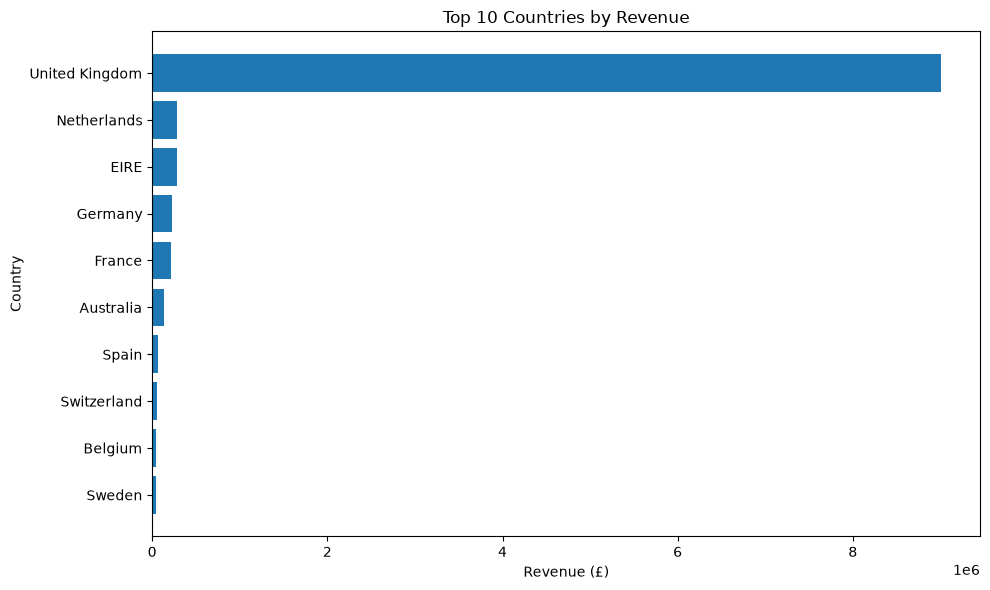

In [12]:
country_analysis = (
    clean_df.groupby("Country")
    .agg(
        Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum"),
        Unique_Invoices=("InvoiceNo", "nunique"),
        Unique_Customers=("CustomerID", "nunique")
    )
    .reset_index()
    .sort_values("Revenue", ascending=False)
)

country_analysis["Revenue_Share_Pct"] = (
    country_analysis["Revenue"] / total_revenue * 100
    if total_revenue else 0
)

display(country_analysis.head(10))
country_analysis.to_csv(
    TABLE_DIR / "country_analysis.csv", index=False
)

plot_countries = country_analysis.head(10).sort_values("Revenue")

plt.figure(figsize=(10, 6))
plt.barh(plot_countries["Country"], plot_countries["Revenue"])
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "top_10_countries.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

,CustomerID,Revenue,Units_Sold,Unique_Invoices,First_Purchase,Last_Purchase
1689,14646.0,280206.02,196915,73,2010-12-20 10:09:00,2011-12-08 12:12:00
4201,18102.0,259657.30,64124,60,2010-12-07 16:42:00,2011-12-09 11:50:00
3728,17450.0,194390.79,69973,46,2010-12-07 09:23:00,2011-12-01 13:29:00
3008,16446.0,168472.50,80997,2,2011-05-18 09:52:00,2011-12-09 09:15:00
1879,14911.0,143711.17,80240,201,2010-12-01 14:05:00,2011-12-08 15:54:00
55,12415.0,124914.53,77374,21,2011-01-06 11:12:00,2011-11-15 14:22:00
1333,14156.0,117210.08,57768,55,2010-12-03 11:48:00,2011-11-30 10:54:00
3771,17511.0,91062.38,64549,31,2010-12-01 10:19:00,2011-12-07 10:12:00
2702,16029.0,80850.84,40108,63,2010-12-01 09:57:00,2011-11-01 10:27:00
0,12346.0,77183.60,74215,1,2011-01-18 10:01:00,2011-01-18 10:01:00


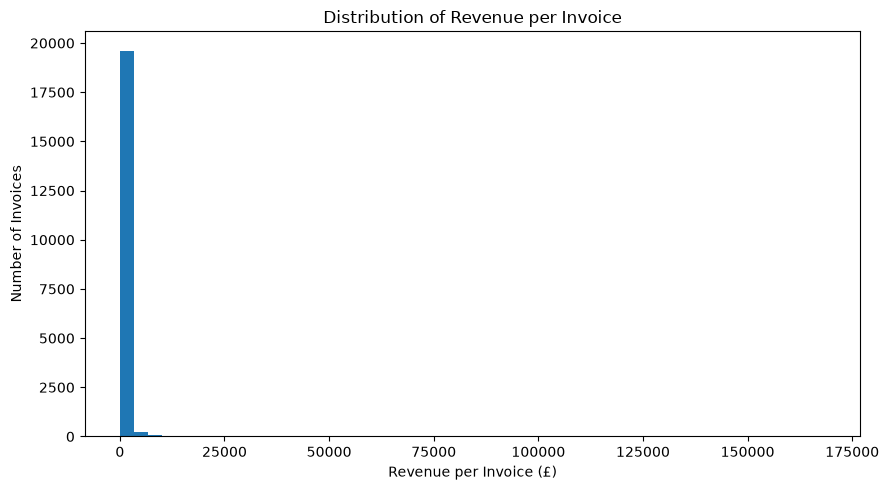

In [13]:
customer_df = clean_df.dropna(subset=["CustomerID"]).copy()

customer_analysis = (
    customer_df.groupby("CustomerID")
    .agg(
        Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum"),
        Unique_Invoices=("InvoiceNo", "nunique"),
        First_Purchase=("InvoiceDate", "min"),
        Last_Purchase=("InvoiceDate", "max")
    )
    .reset_index()
    .sort_values("Revenue", ascending=False)
)

top_customers = customer_analysis.head(10).copy()
display(top_customers)

top_customers.to_csv(
    TABLE_DIR / "top_10_customers.csv", index=False
)

invoice_analysis = (
    clean_df.groupby("InvoiceNo")
    .agg(
        Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum"),
        Invoice_Date=("InvoiceDate", "min"),
        Country=("Country", "first")
    )
    .reset_index()
)

invoice_analysis.to_csv(
    TABLE_DIR / "invoice_analysis.csv", index=False
)

plt.figure(figsize=(9, 5))
plt.hist(invoice_analysis["Revenue"], bins=50)
plt.title("Distribution of Revenue per Invoice")
plt.xlabel("Revenue per Invoice (£)")
plt.ylabel("Number of Invoices")
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "invoice_revenue_distribution.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

,Weekday,Revenue,Unique_Invoices
0,Monday,1775782.071,3126.0
1,Tuesday,2175700.511,3554.0
2,Wednesday,1847074.380,3690.0
3,Thursday,2199292.570,4246.0
4,Friday,1837470.491,3140.0
5,Saturday,NaN,NaN
6,Sunday,806790.781,2204.0


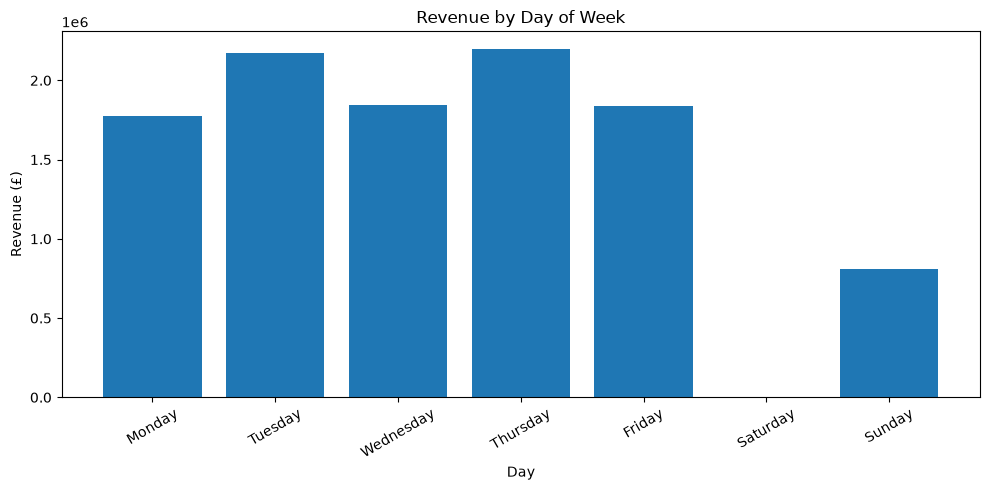

In [14]:
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_analysis = (
    clean_df.assign(
        Weekday=clean_df["InvoiceDate"].dt.day_name()
    )
    .groupby("Weekday")
    .agg(
        Revenue=("Revenue", "sum"),
        Unique_Invoices=("InvoiceNo", "nunique")
    )
    .reindex(weekday_order)
    .reset_index()
)

display(weekday_analysis)
weekday_analysis.to_csv(
    TABLE_DIR / "weekday_analysis.csv", index=False
)

plt.figure(figsize=(10, 5))
plt.bar(
    weekday_analysis["Weekday"],
    weekday_analysis["Revenue"]
)
plt.title("Revenue by Day of Week")
plt.xlabel("Day")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "revenue_by_weekday.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [15]:
best_month = monthly_sales.loc[monthly_sales["Revenue"].idxmax()]
lowest_month = monthly_sales.loc[monthly_sales["Revenue"].idxmin()]
top_country = country_analysis.iloc[0]
top_product = product_analysis.iloc[0]

findings = [
    "ONLINE RETAIL EDA — KEY FINDINGS",
    "",
    f"Cleaned rows: {len(clean_df):,}",
    f"Total revenue: £{total_revenue:,.2f}",
    f"Total units sold: {total_units:,.0f}",
    f"Unique invoices: {total_invoices:,}",
    f"Customers with ID: {total_customers:,}",
    f"Unique products: {total_products:,}",
    f"Countries: {total_countries:,}",
    "",
    f"Highest-revenue month: {best_month['YearMonth']} "
    f"(£{best_month['Revenue']:,.2f})",
    f"Lowest-revenue month: {lowest_month['YearMonth']} "
    f"(£{lowest_month['Revenue']:,.2f})",
    f"Top country: {top_country['Country']} "
    f"(£{top_country['Revenue']:,.2f})",
    f"Top product by revenue: {top_product['Product_Description']} "
    f"(£{top_product['Revenue']:,.2f})"
]

findings_text = "\n".join(findings)
print(findings_text)

(OUTPUT_DIR / "key_findings.txt").write_text(
    findings_text,
    encoding="utf-8"
)

ONLINE RETAIL EDA — KEY FINDINGS

Cleaned rows: 524,878
Total revenue: £10,642,110.80
Total units sold: 5,572,420
Unique invoices: 19,960
Customers with ID: 4,338
Unique products: 3,922
Countries: 38

Highest-revenue month: 2011-11 (£1,503,866.78)
Lowest-revenue month: 2011-02 (£522,545.56)
Top country: United Kingdom (£9,001,744.09)
Top product by revenue: DOTCOM POSTAGE (£206,248.77)


388

In [16]:
# Simpan seluruh tabel analisis terbaru
tables_to_save = {
    "business_kpis.csv": kpi,
    "monthly_sales_trend.csv": monthly_sales,
    "top_10_products.csv": top_products,
    "top_10_products_by_quantity.csv": top_by_quantity,
    "country_analysis.csv": country_analysis,
    "top_10_customers.csv": top_customers,
    "invoice_analysis.csv": invoice_analysis,
    "weekday_analysis.csv": weekday_analysis,
    "cleaning_summary.csv": cleaning_report
}

for filename, table in tables_to_save.items():
    table.to_csv(TABLE_DIR / filename, index=False)

# Simpan data bersih untuk penggunaan lokal
clean_df.to_csv(
    TABLE_DIR / "online_retail_clean.csv",
    index=False
)

print("=== OUTPUT FILES ===")
for folder in [FIGURE_DIR, TABLE_DIR]:
    print(f"\n{folder.name}/")
    for path in sorted(folder.iterdir()):
        print(f"- {path.name} ({path.stat().st_size:,} bytes)")

print("\nKey findings:", (OUTPUT_DIR / "key_findings.txt").exists())

=== OUTPUT FILES ===

figures/
- invoice_revenue_distribution.png (48,588 bytes)
- monthly_revenue_trend.png (115,575 bytes)
- revenue_by_weekday.png (53,031 bytes)
- top_10_countries.png (56,235 bytes)
- top_10_products.png (80,529 bytes)

tables/
- business_kpis.csv (212 bytes)
- cleaning_summary.csv (243 bytes)
- country_analysis.csv (1,958 bytes)
- invoice_analysis.csv (1,084,173 bytes)
- monthly_sales_trend.csv (699 bytes)
- online_retail_clean.csv (58,943,293 bytes)
- top_10_customers.csv (750 bytes)
- top_10_products.csv (538 bytes)
- top_10_products_by_quantity.csv (629 bytes)
- weekday_analysis.csv (210 bytes)

Key findings: True
